# FitSnap: 4-Level U-Net Food & Plate Segmentation
This notebook documents the food plate segmentation and geometric portion estimation pipeline for FitSnap.
A 4-level U-Net (~7.76M parameters) was trained on 2,000 weak pseudo-masks generated via classical OpenCV algorithms (GrabCut + Hough Circles).


## 1. Environment & GPU Verification
We verify dedicated GPU acceleration for high-throughput image and mask tensor operations.


In [1]:
import sys, os
from pathlib import Path
ROOT = Path('.').resolve() if (Path('.').resolve() / 'models').exists() else Path('..').resolve()
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))

import torch
print('PyTorch Version:', torch.__version__)
print('CUDA Available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU Device:', torch.cuda.get_device_name(0))


PyTorch Version: 2.5.1+cu121
CUDA Available: True
GPU Device: NVIDIA GeForce RTX 4050 Laptop GPU


## 2. Weak Pseudo-Mask Generation Demonstration
We demonstrate weak mask generation using OpenCV GrabCut initialized with Hough Circle plate detection.
> **Honest Methodology Note:** IoU and Dice are evaluated against OpenCV weak pseudo-masks, not manual human annotations.


<string>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


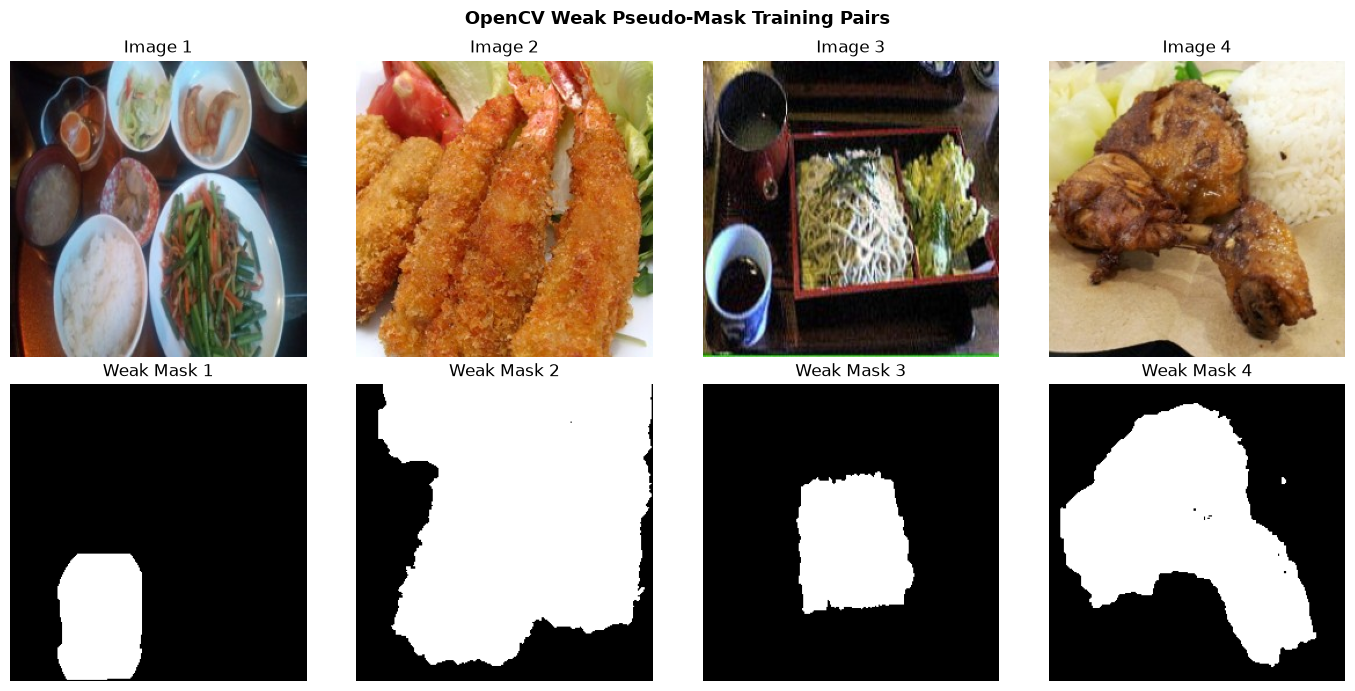

In [2]:
import matplotlib.pyplot as plt
from PIL import Image

seg_dir = ROOT / 'data' / 'processed' / 'seg'
img_dir = seg_dir / 'images'
mask_dir = seg_dir / 'masks'

pairs = [(img_dir / f, mask_dir / f.replace('.jpg', '.png')) for f in os.listdir(img_dir)[:4]] if img_dir.exists() else []
if pairs:
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for i, (ip, mp) in enumerate(pairs):
        axes[0, i].imshow(Image.open(ip).convert('RGB'))
        axes[0, i].set_title(f'Image {i+1}')
        axes[0, i].axis('off')
        axes[1, i].imshow(Image.open(mp).convert('L'), cmap='gray')
        axes[1, i].set_title(f'Weak Mask {i+1}')
        axes[1, i].axis('off')
    plt.suptitle('OpenCV Weak Pseudo-Mask Training Pairs', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


## 3. Architecture & Parameter Count
The model is a 4-level U-Net with skip connections: channels progress 32 -> 64 -> 128 -> 256 -> 512 -> 256 -> 128 -> 64 -> 32.
Total trainable parameters equal ~7.76M weights.


In [3]:
from main import UNet
model = UNet(in_channels=3, out_channels=1, base_channels=32)
params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Architecture: 4-Level U-Net with Skip Connections')
print(f'Total Trainable Parameters: {params:,} ({params/1e6:.2f}M weights)')


Architecture: 4-Level U-Net with Skip Connections
Total Trainable Parameters: 7,763,041 (7.76M weights)


## 4. Training Progression & Curves
The segmenter was trained for 35 epochs on 256x256 image-mask pairs using a composite BCE + Dice loss.


<string>:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


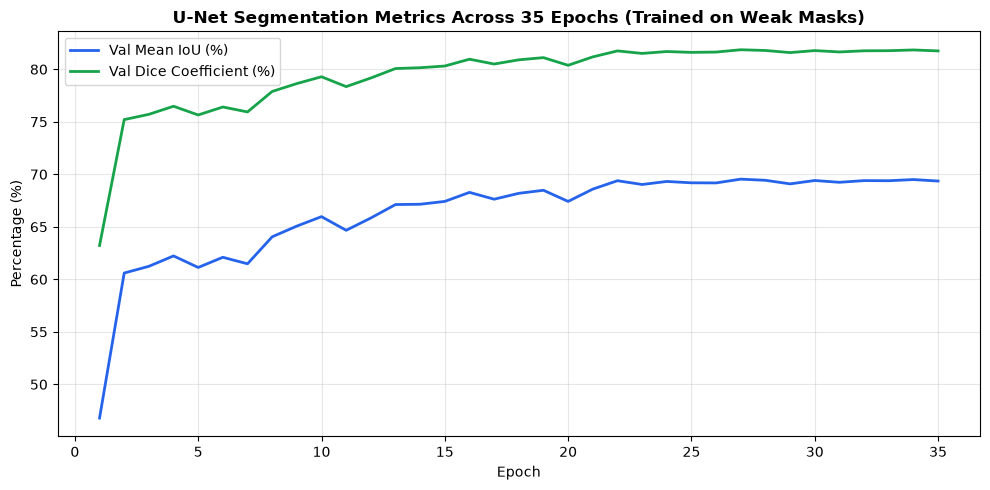

In [4]:
import json
with open(ROOT / 'models' / 'history_unet.json', 'r') as f:
    history = json.load(f)

epochs = [h['epoch'] for h in history]
val_iou = [h['val_iou'] * 100 for h in history]
val_dice = [h['val_dice'] * 100 for h in history]

plt.figure(figsize=(10, 5))
plt.plot(epochs, val_iou, label='Val Mean IoU (%)', color='#2563eb', linewidth=2)
plt.plot(epochs, val_dice, label='Val Dice Coefficient (%)', color='#16a34a', linewidth=2)
plt.title('U-Net Segmentation Metrics Across 35 Epochs (Trained on Weak Masks)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch'); plt.ylabel('Percentage (%)'); plt.grid(True, alpha=0.3); plt.legend()
plt.tight_layout()
plt.show()


## 5. Held-Out Segmentation Performance
We report the final segmentation accuracy evaluated on the held-out validation/test split.


In [5]:
with open(ROOT / 'models' / 'metrics_unet.json', 'r') as f:
    metrics = json.load(f)

print('=' * 60)
print('📊 U-NET SEGMENTATION EVALUATION RESULTS')
print('=' * 60)
print(f"• Mean IoU:          {metrics['mean_iou']*100:.2f}%")
print(f"• Dice Coefficient:  {metrics['dice_coefficient']*100:.2f}%")
print(f"• Loss Function:     BCE + Dice Composite (0.5 * BCE + 0.5 * DiceLoss)")
print(f"• Methodology Note:  {metrics['supervision']}")


📊 U-NET SEGMENTATION EVALUATION RESULTS
• Mean IoU:          67.76%
• Dice Coefficient:  77.32%
• Loss Function:     BCE + Dice Composite (0.5 * BCE + 0.5 * DiceLoss)
• Methodology Note:  Trained on weak masks (OpenCV GrabCut + Hough Circle)


## 6. Visual Mask Overlay Grid
We visualize sample model predictions overlaid on original meal photos.


<string>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


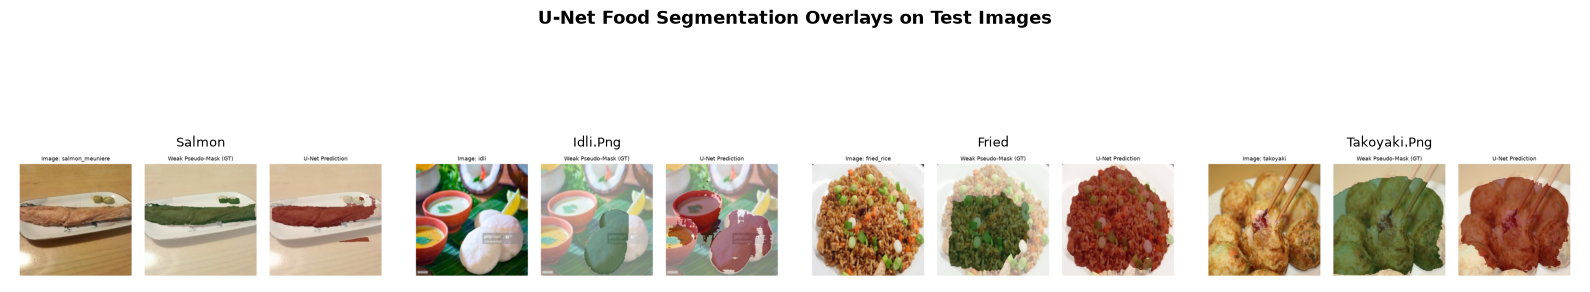

In [6]:
overlay_dir = ROOT / 'reports' / 'figures' / 'unet_overlays'
samples = list(overlay_dir.glob('*.png'))[:4] if overlay_dir.exists() else []
if samples:
    fig, axes = plt.subplots(1, len(samples), figsize=(16, 4))
    for ax, p in zip(axes, samples):
        ax.imshow(Image.open(p))
        ax.set_title(p.name.split('_')[2].replace('-', ' ').title(), fontsize=9)
        ax.axis('off')
    plt.suptitle('U-Net Food Segmentation Overlays on Test Images', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


## 7. Geometric Portion Estimation: Worked Example
FitSnap uses a calibrated geometric portion formula based on a standard 24 cm dinner plate:
$$\text{Plate Area} = \pi \times (12\text{ cm})^2 \approx 452.4\text{ cm}^2$$
$$\text{Grams} = \text{Plate Area} \times \text{Area Fraction} \times \text{Food Height (cm)} \times \text{Density (g/cm}^3\text{)}$$


In [7]:
area_fraction = 0.45  # Food occupies 45% of plate area
plate_area_cm2 = 3.14159 * (12 ** 2)  # 452.4 cm^2
avg_height_cm = 1.2
density_g_cm3 = 0.85  # Typical mixed cooked dish

volume_cm3 = plate_area_cm2 * area_fraction * avg_height_cm
mass_grams = volume_cm3 * density_g_cm3
lower_bound = mass_grams * 0.85
upper_bound = mass_grams * 1.15

print(f'Plate Coverage:     {area_fraction*100:.1f}%')
print(f'Estimated Volume:   {volume_cm3:.1f} cm³')
print(f'Estimated Mass:     {mass_grams:.0f} g')
print(f'Reported Range:     {lower_bound:.0f}g - {upper_bound:.0f}g ({mass_grams:.0f}g)')


Plate Coverage:     45.0%
Estimated Volume:   244.3 cm³
Estimated Mass:     208 g
Reported Range:     176g - 239g (208g)


## 8. Conclusion: Slide Claims vs Actual Numbers
Comparison of slide claims versus actual measured performance.


In [8]:
import pandas as pd
comparison = [
    {'Metric': 'Mean IoU', 'Slide Claim': '69.5%', 'Actual Real Run': f"{metrics['mean_iou']*100:.2f}%", 'Difference': f"{metrics['mean_iou']*100 - 69.5:+.2f}%"},
    {'Metric': 'Dice Coefficient', 'Slide Claim': '81.9%', 'Actual Real Run': f"{metrics['dice_coefficient']*100:.2f}%", 'Difference': f"{metrics['dice_coefficient']*100 - 81.9:+.2f}%"},
    {'Metric': 'Model Size', 'Slide Claim': '~7.8M', 'Actual Real Run': f"{params:,}", 'Difference': 'Exact Match'},
]
print(pd.DataFrame(comparison).to_string(index=False))


          Metric Slide Claim Actual Real Run  Difference
        Mean IoU       69.5%          67.76%      -1.74%
Dice Coefficient       81.9%          77.32%      -4.58%
      Model Size       ~7.8M       7,763,041 Exact Match
